In [20]:
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import simpledialog
import re
import sys
from pathlib import Path
from datetime import timedelta

# MANUAL input to change
your_ing_id = "XO21BM"
# Optional: set a specific date
# date = datetime.strptime('2024', "%Y")

########################################################################################################################

# DO NOT CHANGE ANYTHING BELOW - only when developing code

# Determine operating system
is_windows = os.name == 'nt'

# Set base directory based on OS
if is_windows:
    base_dir = Path(f"C:/Users/{your_ing_id}/ING")
else:
    base_dir = Path(f"/Users/{your_ing_id}/Documents")


#################################### Add directory path correctly to onedrive folder ####################################################

# directories

current_directory = os.getcwd()
dir_in_events = Path("/Users/XO21BM/Library/CloudStorage/OneDrive-SharedLibraries-ING/PMR NL - Weekly NFR/Data/Events/")
dir_out = Path(current_directory).parent / "Output"


In [21]:
# Functions Aleksandra to extract the lastest dump

# Determine current week from data directory
current_week = []

files = os.listdir(dir_in_events)
week_d = []

for file in files:
    match = re.search(r'W(\d+)', file)
    if match:
        week_number = int(match.group(1))
        week_d.append(week_number)

if not week_d:
    raise ValueError("No week-numbered files found.")

max_week = max(week_d)
current_week.append(max_week)

current_week = list(set(current_week))

if len(current_week) > 1:
    raise ValueError("Missing File. Please check data folders")
else:
    current_week = current_week[0]

# Load data
file_name = f"Full Dump Events W{current_week}.csv"
file_path = dir_in_events / file_name

df = pd.read_csv(file_path, encoding='utf-16', sep='\t', engine='python')

In [22]:
#### what kind of date columns are available 

# select all date columns and calculate delta in days | start event - discovery - creation date - end event - close 
# leading date column NFRD: creation date

# never made this copies before but pandas complains..
df = df.copy()

selected_dates = df[['Event Start Date', 'Event End Date', 'Discovery Date', 'Close Date', 'Creation Date', 
                     'Identifier', 'NFR Area to use 1', 'NFR Area to use 2', 'Potential Gross Loss (EUR)', 'GROSS LOSS', 'NET LOSS',
                    'Parent Path', 'Product Level 1', 'Product Level 2', 'Fraud Reporting Level 1', 'Fraud Reporting Level 2']].copy()

date_columns = ['Event Start Date', 'Discovery Date', 'Creation Date', 'Event End Date', 'Close Date']
for col in date_columns:
    selected_dates[col] = pd.to_datetime(selected_dates[col], errors='coerce')

# filter out fraud cases
filtered_dates = selected_dates[
    selected_dates['NFR Area to use 1'] == 'External Fraud Risk'].copy()


filtered_dates['Tribe'] = filtered_dates['Parent Path'].str.extract(r'(Tribe.*)')
filtered_dates['Business line'] = filtered_dates['Parent Path'].str.extract(r'/ING BANK/NL/(.*?)(?=/Tribe)')

filtered_dates['Discovery_minus_Start'] = (filtered_dates['Discovery Date'] - filtered_dates['Event Start Date']).dt.days
filtered_dates['Creation_minus_Discovery'] = (filtered_dates['Creation Date'] - filtered_dates['Discovery Date']).dt.days
filtered_dates['Close_minus_EventEnd'] = (filtered_dates['Close Date'] - filtered_dates['Event End Date']).dt.days
filtered_dates['Close_minus_EventStart'] = (filtered_dates['Close Date'] - filtered_dates['Event Start Date']).dt.days
filtered_dates['Close_minus_Discovery'] = (filtered_dates['Close Date'] - filtered_dates['Discovery Date']).dt.days
filtered_dates['Close_minus_Creation'] = (filtered_dates['Close Date'] - filtered_dates['Creation Date']).dt.days
filtered_dates['Creation_Year'] = filtered_dates['Creation Date'].dt.year


In [23]:
## lets get some meaning out of this per year, business line & tribe

# Group by Business Line, Tribe, and Creation Year
grouped = filtered_dates.groupby(
    ['Business line', 'Tribe', 'Creation_Year']
).agg({
    'Discovery_minus_Start': 'mean',
    'Creation_minus_Discovery': 'mean',
    'Close_minus_EventStart': 'mean',
    'Close_minus_EventEnd': 'mean',
    'Close_minus_Discovery': 'mean',
    'Close_minus_Creation': 'mean',
    'GROSS LOSS': 'mean',
    'NET LOSS': 'mean',
    'Identifier': 'count',
    
}).reset_index()

# Rename columns for clarity
grouped.rename(columns={
    'Discovery_minus_Start': 'Avg_Discovery_start',
    'Creation_minus_Discovery': 'Avg_Creation_minus_Discovery',
    'Close_minus_EventStart': 'Avg_Close_to_Start_Days',
    'Close_minus_EventEnd' : 'Avg_Close_minus_EventEnd',
    'Close_minus_Discovery': 'Avg_Close_minus_Discovery_Days',
    'Close_minus_Creation' : 'Avg_close_minus_creation',
    'GROSS LOSS': 'Avg_Gross_Loss_EUR',
    'NET LOSS': 'Avg_Net_Loss_EUR',
    'Identifier': 'counter'
}, inplace=True)

grouped = grouped.round(0)
grouped

,Business line,Tribe,Creation_Year,Avg_Discovery_start,Avg_Creation_minus_Discovery,Avg_Close_to_Start_Days,Avg_Close_minus_EventEnd,Avg_Close_minus_Discovery_Days,Avg_close_minus_creation,Avg_Gross_Loss_EUR,Avg_Net_Loss_EUR,counter
0,Business Banking,Tribe Business Lending,2012,242.0,825.0,3806.0,3806.0,3564.0,2739.0,137500.0,137500.0,2
1,Business Banking,Tribe Business Lending,2013,2.0,22.0,606.0,603.0,604.0,583.0,286022.0,286022.0,8
2,Business Banking,Tribe Business Lending,2014,194.0,47.0,380.0,380.0,186.0,138.0,639152.0,639152.0,12
3,Business Banking,Tribe Business Lending,2015,715.0,26.0,958.0,674.0,244.0,217.0,245191.0,245191.0,25
4,Business Banking,Tribe Business Lending,2016,357.0,25.0,1033.0,685.0,677.0,651.0,371724.0,371724.0,11
...,...,...,...,...,...,...,...,...,...,...,...,...
78,Retail Banking,Tribe Mortgages,2023,0.0,16.0,198.0,198.0,198.0,181.0,0.0,0.0,1
79,Retail Banking,Tribe Mortgages,2024,52.0,92.0,338.0,270.0,244.0,134.0,373968.0,217966.0,61
80,Retail Banking,Tribe Mortgages,2025,0.0,28.0,273.0,273.0,273.0,159.0,470497.0,413466.0,55
81,Retail Banking,Tribe Mortgages/Tribe Westland Utrecht Bank,2015,0.0,687.0,1002.0,1311.0,1002.0,315.0,56237.0,56237.0,9


In [16]:
# pivot tribe * year * duration per stage

# Clean and convert year
filtered_dates['Creation_Year'] = pd.to_numeric(filtered_dates['Creation_Year'].astype(str).str.strip(), errors='coerce')

# Filter for target years
# just two years to check if its helpful
filtered_df = filtered_dates[filtered_dates['Creation_Year'].isin([2023, 2024, 2025])]

excluded_tribes = ['Tribe Fraud and Cyber Security', 'Tribe Payments']

filtered_df = filtered_df[
    (~filtered_df['Tribe'].isin(excluded_tribes)) &
    ((filtered_df['Creation_Year'] == 2023) | (filtered_df['Creation_Year'] == 2024) | (filtered_df['Creation_Year'] == 2025)) 
]


# Group
grouped_fraud_type_duration = filtered_df.groupby(
    ['Fraud Reporting Level 1', 'Creation_Year', 'Tribe']
).agg({
    'Discovery_minus_Start': 'mean',
    'Creation_minus_Discovery': 'mean',
    'Close_minus_EventStart': 'mean',
    'Close_minus_EventEnd': 'mean',
    'Close_minus_Discovery': 'mean',
    'Close_minus_Creation': 'mean',
    'GROSS LOSS': 'mean',
    'NET LOSS': 'mean',
    'Identifier': 'count',
}).reset_index()

grouped_fraud_type_duration = grouped_fraud_type_duration.round(0)

In [17]:
# create the file
grouped_fraud_type_duration.to_csv('grouped_fraud_type_duration.csv', index=False)
grouped_fraud_type_duration

grouped_fraud_type_duration_wide = grouped_fraud_type_duration.pivot(index='Creation_Year', columns='Tribe', values=['Discovery_minus_Start',
                                                                                                              'Creation_minus_Discovery',
                                                                                                              'Close_minus_EventStart',
                                                                                                              'Close_minus_EventEnd',
                                                                                                              'Close_minus_Discovery',
                                                                                                              'Close_minus_Creation',
                                                                                                              'GROSS LOSS',
                                                                                                              'NET LOSS',
                                                                                                              'Identifier'])
grouped_fraud_type_duration_wide
grouped_fraud_type_duration_wide.to_csv('grouped_fraud_type_duration_wide.csv', index=False)
grouped_fraud_type_duration_wide

Discovery_minus_Start                       \
Tribe         Tribe Business Lending Tribe Consumer Loans   
Creation_Year                                               
2023                            19.0                 16.0   
2024                             0.0                  0.0   
2025                             0.0                  3.0   

                                                                         \
Tribe         Tribe Daily Banking and Digital First/Adviesteam Kantoren   
Creation_Year                                                             
2023                                                         4.0          
2024                                                         NaN          
2025                                                         NaN          

                              Creation_minus_Discovery                       \
Tribe         Tribe Mortgages   Tribe Business Lending Tribe Consumer Loans   
Creation_Year                                                                 
2023                      0.0                     23.0                 42.0   
2024                     52.0                     92.0                 17.0   
2025                      0.0                     12.0                 15.0   

                                                                         \
Tribe         Tribe Daily Banking and Digital First/Adviesteam Kantoren   
Creation_Year                                                             
2023                                                        18.0          
2024                                                         NaN          
2025                                                         NaN          

                              Close_minus_EventStart                       \
Tribe         Tribe Mortgages Tribe Business Lending Tribe Consumer Loans   
Creation_Year                                                               
2023                     16.0                   54.0                 19.0   
2024                     92.0                   73.0                 82.0   
2025                     28.0                   20.0                129.0   

               ...                                                GROSS LOSS  \
Tribe          ... Tribe Daily Banking and Digital First/Adviesteam Kantoren   
Creation_Year  ...                                                             
2023           ...                                             5000.0          
2024           ...                                                NaN          
2025           ...                                                NaN          

                                            NET LOSS                       \
Tribe         Tribe Mortgages Tribe Business Lending Tribe Consumer Loans   
Creation_Year                                                               
2023                      0.0                49343.0              31626.0   
2024                 373968.0               100583.0              22017.0   
2025                 470497.0               135623.0              20202.0   

                                                                         \
Tribe         Tribe Daily Banking and Digital First/Adviesteam Kantoren   
Creation_Year                                                             
2023                                                      5000.0          
2024                                                         NaN          
2025                                                         NaN          

                                          Identifier                       \
Tribe         Tribe Mortgages Tribe Business Lending Tribe Consumer Loans   
Creation_Year                                                               
2023                      0.0                   22.0                  8.0   
2024                 217966.0                    6.0                 39.0   
2025                 413466.

In [18]:
# mortgage specific per year:  to explore average time between start - close event date & discovery - close date

grouped

grouped_mortgage_sample = grouped[
    (grouped['Business line'] == 'Retail Banking') &
    ((grouped['Tribe'] == 'Tribe Mortgages') | (grouped['Tribe'] == 'Tribe Mortgages/Tribe Westland Utrecht Bank'))
].copy()


grouped_mortgage_sample[['Avg_Close_to_Start_Days', 'Avg_Gross_Loss_EUR', 'Avg_Net_Loss_EUR', 'Creation_Year', 'Avg_Close_minus_Discovery_Days']] = (
    grouped[['Avg_Close_to_Start_Days', 'Avg_Gross_Loss_EUR', 'Avg_Net_Loss_EUR', 'Creation_Year', 'Avg_Close_minus_Discovery_Days']]
    .round(0)
    .astype('Int64')
)
grouped_mortgage_sample.to_csv('grouped_mortgage_sample.csv', index=False)
grouped_mortgage_sample

,Business line,Tribe,Creation_Year,Avg_Discovery_start,Avg_Creation_minus_Discovery,Avg_Close_to_Start_Days,Avg_Close_minus_EventEnd,Avg_Close_minus_Discovery_Days,Avg_close_minus_creation,Avg_Gross_Loss_EUR,Avg_Net_Loss_EUR,counter
67,Retail Banking,Tribe Mortgages,2012,32.0,498.0,1094,1094.0,1062,564.0,1575102,1575102,2
68,Retail Banking,Tribe Mortgages,2013,6.0,38.0,90,49.0,84,45.0,312667,312667,9
69,Retail Banking,Tribe Mortgages,2014,222.0,48.0,476,360.0,254,205.0,373250,373250,12
70,Retail Banking,Tribe Mortgages,2015,6.0,26.0,179,157.0,172,147.0,259500,259500,12
71,Retail Banking,Tribe Mortgages,2016,54.0,16.0,264,216.0,210,194.0,128481,128481,11
72,Retail Banking,Tribe Mortgages,2017,0.0,2.0,8,6.0,8,6.0,0,0,2
73,Retail Banking,Tribe Mortgages,2018,295.0,149.0,724,299.0,429,280.0,73115,73115,3
74,Retail Banking,Tribe Mortgages,2019,73.0,55.0,342,230.0,270,214.0,8967,8967,18
75,Retail Banking,Tribe Mortgages,2020,30.0,28.0,629,599.0,599,571.0,172216,172216,1
76,Retail Banking,Tribe Mortgages,2021,521.0,51.0,911,388.0,390,339.0,0,0,3


In [15]:
## 2025 external fraud development per month creation year == 2025


# skip all cases with a discovery date >= 2025
# use months of event start date
filtered_year = filtered_dates[filtered_dates['Creation Date'].dt.year >= 2025].copy()
filtered_year['Creation_date_Month'] = filtered_year['Creation Date'].dt.month_name()

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

filtered_year['Creation_date_Month'] = pd.Categorical(
    filtered_year['Creation_date_Month'],
    categories=month_order,
    ordered=True
)


# Group by month
grouped_month_sample = (
    filtered_year.groupby(['Creation_date_Month', 'Fraud Reporting Level 1'])
    .agg({
        'Close_minus_Discovery': 'mean',
        'Close_minus_Creation': 'mean',
        'GROSS LOSS': 'mean',
        'NET LOSS': 'mean',
        'Identifier':'count'
    })
    .reset_index()
    .sort_values(by=['Creation_date_Month', 'GROSS LOSS'], ascending=[True, False])
)

grouped_month_sample[['Close_minus_EventStart', 'Close_minus_Discovery', 'GROSS LOSS', 'NET LOSS']] = (
    grouped_month_sample[['Close_minus_Creation', 'Close_minus_Discovery', 'GROSS LOSS', 'NET LOSS']]
    .round(0)
    .astype('Int64')
)

grouped_month_sample

/var/folders/lv/61fk92ys029066nv5n8t6cw80000gq/T/ipykernel_35063/1030242117.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  filtered_year.groupby(['Creation_date_Month', 'Fraud Reporting Level 1'])


,Creation_date_Month,Fraud Reporting Level 1,Close_minus_Discovery,Close_minus_Creation,GROSS LOSS,NET LOSS,Identifier,Close_minus_EventStart
2,January,Lending Fraud,14,6.528302,16332,3070,108,7
1,January,Card Fraud,4,1.133956,2777,406,322,1
3,January,Transaction Fraud,18,15.500000,725,725,2,16
0,January,Authorised Push Payment Fraud,18,13.169429,178,178,1096,13
4,January,e-Banking Fraud,28,23.000000,0,0,13,23
7,February,Lending Fraud,66,18.647059,30949,9754,18,19
6,February,Card Fraud,6,2.639286,2076,375,281,3
8,February,Transaction Fraud,69,-1.750000,249,249,4,-2
5,February,Authorised Push Payment Fraud,17,12.426802,157,157,900,12
9,February,e-Banking Fraud,39,37.200000,0,0,10,37


In [12]:
grouped_month_sample

### adjust close to creation date ##############################################################

grouped_month_sample.to_csv('grouped_month_sample.csv', index=False)

/var/folders/lv/61fk92ys029066nv5n8t6cw80000gq/T/ipykernel_35063/3267187103.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_df_gross_loss = grouped_month_sample.pivot_table(index='Creation_date_Month', columns='Fraud Reporting Level 1',
/var/folders/lv/61fk92ys029066nv5n8t6cw80000gq/T/ipykernel_35063/3267187103.py:6: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_df_duration = grouped_month_sample.pivot_table(index='Creation_date_Month', columns='Fraud Reporting Level 1',
/var/folders/lv/61fk92ys029066nv5n8t6cw80000gq/T/ipykernel_35063/3267187103.py:9: FutureWarning: The default value of observed=False is deprecated and will change to observed=True 

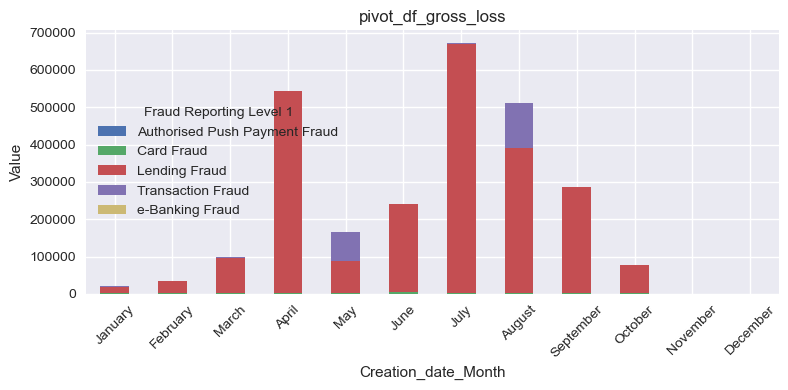

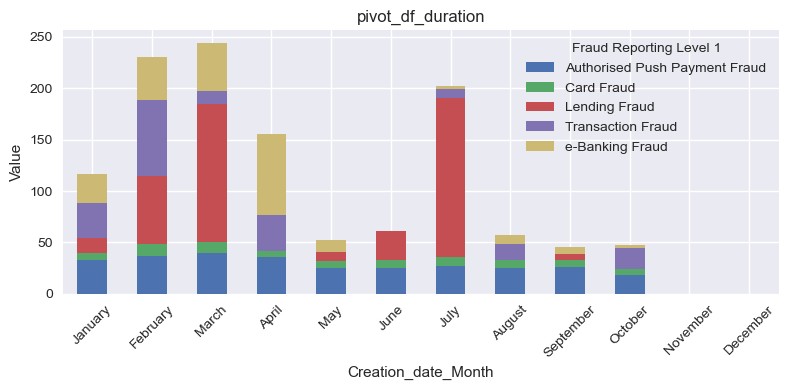

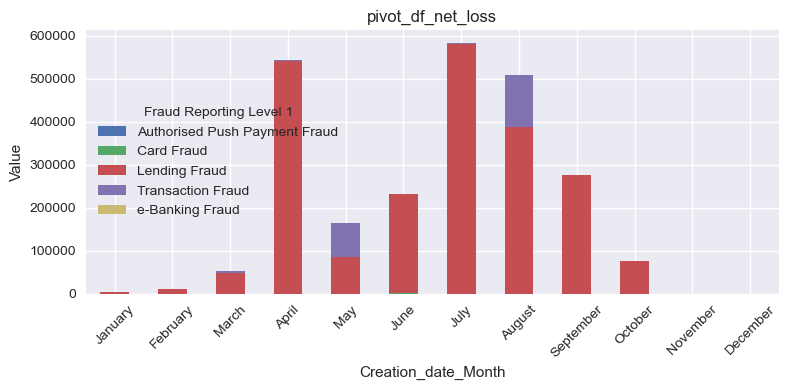

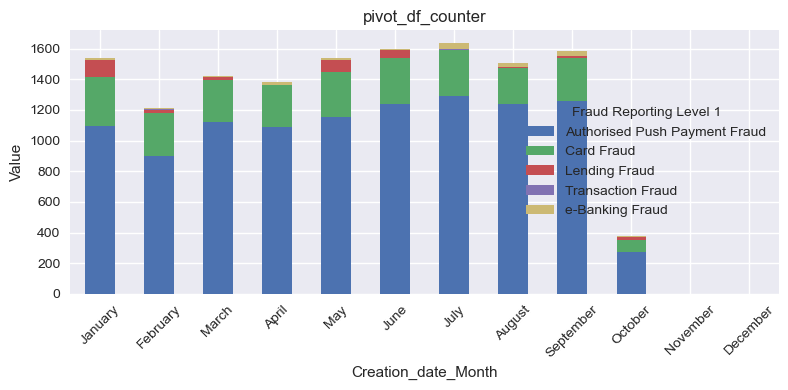

In [13]:
# create pivots 

pivot_df_gross_loss = grouped_month_sample.pivot_table(index='Creation_date_Month', columns='Fraud Reporting Level 1', 
                                                       values='GROSS LOSS', aggfunc='sum').fillna(0)

pivot_df_duration = grouped_month_sample.pivot_table(index='Creation_date_Month', columns='Fraud Reporting Level 1', 
                                                       values='Close_minus_EventStart', aggfunc='sum').fillna(0)

pivot_df_net_loss = grouped_month_sample.pivot_table(index='Creation_date_Month', columns='Fraud Reporting Level 1', 
                                                       values='NET LOSS', aggfunc='sum').fillna(0)

pivot_df_counter = grouped_month_sample.pivot_table(index='Creation_date_Month', columns='Fraud Reporting Level 1', 
                                                       values='Identifier', aggfunc='sum').fillna(0)



pivot_list = [pivot_df_gross_loss, pivot_df_duration, pivot_df_net_loss, pivot_df_counter]  
titles = ['pivot_df_gross_loss', 'pivot_df_duration', 'pivot_df_net_loss', 'pivot_df_counter']

plt.style.use('seaborn-v0_8')  # Apply style once

for i, pivot in enumerate(pivot_list):
    plt.figure(figsize=(8, 4))
    pivot.plot(kind='bar', stacked=True, ax=plt.gca())
    plt.title(titles[i])
    plt.xlabel(pivot.index.name if pivot.index.name else 'Index')
    plt.ylabel('Value')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [ ]:
# create csv's to manipulate in excel 
pivot_list = [pivot_df_gross_loss, pivot_df_duration, pivot_df_net_loss, pivot_df_counter]
pivot_names = ["gross_loss", "duration", "net_loss", "counter"]


output_dir = Path.cwd() / "Output"
output_dir.mkdir(exist_ok=True)


for df, name in zip(pivot_list, pivot_names):
    if isinstance(df, pd.DataFrame):
        file_path = output_dir / f"{name}.csv"
        df.to_csv(file_path, index=True)
        print(f"✅ Saved: {file_path}")
    else:
        print(f"⚠️ Skipped {name}: not a valid DataFrame")


In [ ]:
# and now one for mortgages per month with specifically development gross to net loss per different stages
# take all the cases with a discovery day in 2024 and then analyse all the date values
# this is for the comparison 2024 / 2025 gross - net loss mortgages. Run it twice with the right year selected

filtered_dates_mortgage = filtered_dates.loc[
    (filtered_dates['Business line'] == 'Retail Banking') &
    (filtered_dates['Tribe'] == 'Tribe Mortgages') &
    (filtered_dates['Creation Date'].dt.year == 2025)
].copy()

#filtered_dates_mortgage

filtered_dates_mortgage['Creation_date_Month'] = filtered_dates_mortgage['Creation Date'].dt.month_name()

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

filtered_dates_mortgage['Creation_date_Month'] = pd.Categorical(
    filtered_dates_mortgage['Creation_date_Month'],
    categories=month_order,
    ordered=True
)

#filtered_dates_mortgage

# Group by month
filtered_dates_mortgage_grouped_2025= (
    filtered_dates_mortgage.groupby(['Creation_date_Month'])
    .agg({
        'Close_minus_EventStart': 'mean',
        'Close_minus_Discovery': 'mean',
        'GROSS LOSS': 'mean',
        'NET LOSS': 'mean',
        'Identifier':'count'
    })
    .reset_index()
    .sort_values(by=['Creation_date_Month', 'GROSS LOSS'], ascending=[True, False])
    .round(1)
)
filtered_dates_mortgage_grouped_2025

In [ ]:
filtered_dates_mortgage_grouped_2025.to_csv('filtered_dates_mortgage_grouped_2025.csv', index=False)

In [ ]:
# in how many

filtered_dates_mortgage

In [ ]:
# Group by month
filtered_dates_mortgage_grouped_2025= (
    filtered_dates_mortgage.groupby(['Creation_date_Month'])
    .agg({
        'Close_minus_EventStart': 'mean',
        'Close_minus_Discovery': 'mean',
        'GROSS LOSS': 'mean',
        'NET LOSS': 'mean',
        'Identifier':'count'
    })
    .reset_index()
    .sort_values(by=['Creation_date_Month', 'GROSS LOSS'], ascending=[True, False])
    .round(1)
)
filtered_dates_mortgage_grouped_2025